# EDA — Retailrocket (clickstream)

Exploration du comportemental : types d'événements, sparsité des interactions par visiteur (le calcul qui a mené à la détection de visiteurs atypiques dans `analytics/recommend_retailrocket.py`), funnel brut.

In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv
from sqlalchemy import create_engine
import pandas as pd
import matplotlib.pyplot as plt

load_dotenv()  # cherche .env dans le répertoire courant puis ses parents
engine = create_engine(os.environ["DATABASE_URL"])
plt.rcParams["figure.figsize"] = (9, 4)

## Volumétrie et types d'événements

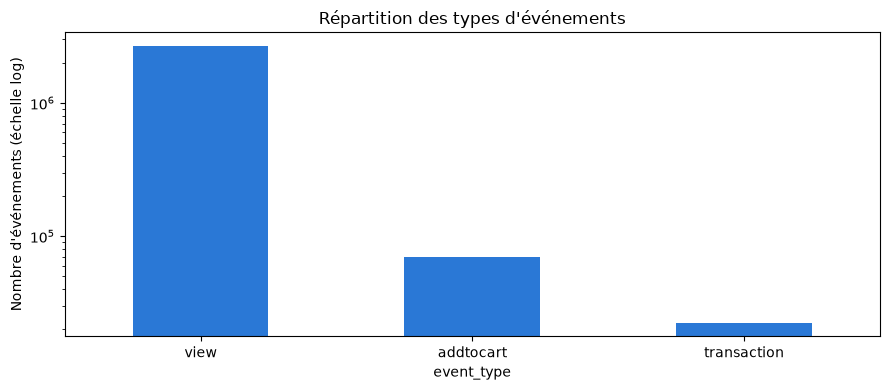

,event_type,n
0,view,2664312
1,addtocart,69332
2,transaction,22457


In [2]:
events_par_type = pd.read_sql(
    "SELECT event_type, COUNT(*) AS n FROM retailrocket.events GROUP BY event_type ORDER BY n DESC", engine)
ax = events_par_type.set_index("event_type")["n"].plot.bar(color="#2a78d6", logy=True)
ax.set_ylabel("Nombre d'événements (échelle log)")
ax.set_title("Répartition des types d'événements")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
events_par_type

## Sparsité des interactions par visiteur

79,5% des visiteurs n'interagissent qu'avec un seul produit distinct — aucune contribution possible à la co-occurrence item-item. La longue traîne à droite (jusqu'à 3814 produits pour un seul visiteur) correspond aux profils atypiques (bots/crawlers) exclus du calcul de similarité (seuil >200 produits).

79.5% des visiteurs n'ont interagi qu'avec un seul produit
Maximum observé : 3814 produits distincts pour un même visiteur


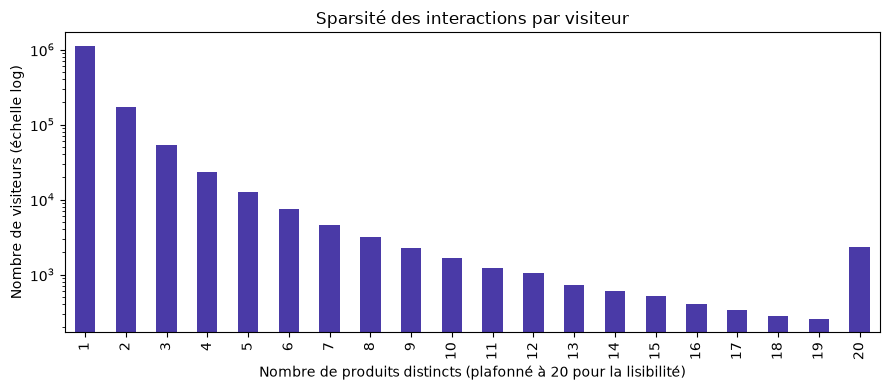

In [3]:
items_par_visiteur = pd.read_sql("""
    SELECT visitor_id, COUNT(DISTINCT item_id) AS nb_items
    FROM retailrocket.events GROUP BY visitor_id
""", engine)

pct_mono_item = (items_par_visiteur["nb_items"] == 1).mean() * 100
print(f"{pct_mono_item:.1f}% des visiteurs n'ont interagi qu'avec un seul produit")
print(f"Maximum observé : {items_par_visiteur['nb_items'].max()} produits distincts pour un même visiteur")

ax = items_par_visiteur["nb_items"].clip(upper=20).value_counts().sort_index().plot.bar(
    color="#4a3aa7", logy=True)
ax.set_xlabel("Nombre de produits distincts (plafonné à 20 pour la lisibilité)")
ax.set_ylabel("Nombre de visiteurs (échelle log)")
ax.set_title("Sparsité des interactions par visiteur")
plt.tight_layout()
plt.show()

## Volume d'événements dans le temps

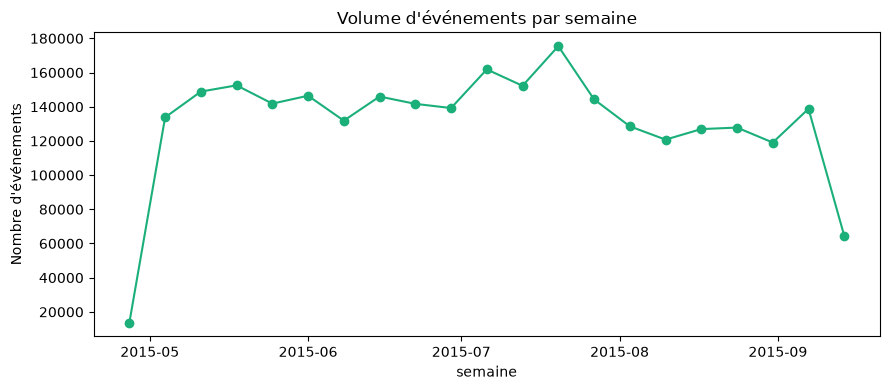

In [4]:
par_semaine = pd.read_sql("""
    SELECT date_trunc('week', event_time)::date AS semaine, COUNT(*) AS n
    FROM retailrocket.events GROUP BY semaine ORDER BY semaine
""", engine)
ax = par_semaine.set_index("semaine")["n"].plot(color="#1baf7a", marker="o")
ax.set_ylabel("Nombre d'événements")
ax.set_title("Volume d'événements par semaine")
plt.tight_layout()
plt.show()

## Funnel brut (visiteurs uniques par étape)

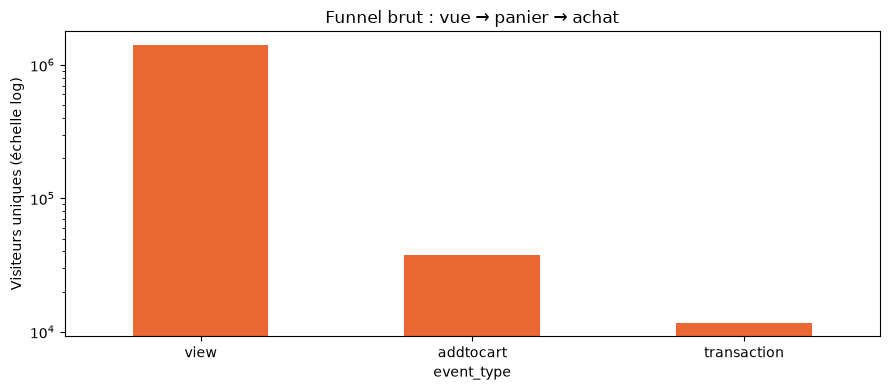

,event_type,visiteurs_uniques
2,view,1404179
0,addtocart,37722
1,transaction,11719


In [5]:
funnel_brut = pd.read_sql("""
    SELECT event_type, COUNT(DISTINCT visitor_id) AS visiteurs_uniques
    FROM retailrocket.events GROUP BY event_type
""", engine)
ordre = pd.CategoricalDtype(["view", "addtocart", "transaction"], ordered=True)
funnel_brut["event_type"] = funnel_brut["event_type"].astype(ordre)
funnel_brut = funnel_brut.sort_values("event_type")
ax = funnel_brut.set_index("event_type")["visiteurs_uniques"].plot.bar(color="#eb6834", logy=True)
ax.set_ylabel("Visiteurs uniques (échelle log)")
ax.set_title("Funnel brut : vue → panier → achat")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
funnel_brut